Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 32)                  │           7,296 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 10, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 10, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 10, 24)              │             792 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 16,408 (64.09 KB)

 Trainable params: 16,408 (64.09 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 0.0174 - mae: 0.0781 - val_loss: 0.0075 - val_mae: 0.0513
Epoch 2/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0077 - mae: 0.0505 - val_loss: 0.0070 - val_mae: 0.0483
Epoch 3/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0074 - mae: 0.0491 - val_loss: 0.0070 - val_mae: 0.0484
Epoch 4/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0072 - mae: 0.0483 - val_loss: 0.0068 - val_mae: 0.0475
Epoch 5/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0071 - mae: 0.0480 - val_loss: 0.0067 - val_mae: 0.0475
Epoch 6/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0070 - mae: 0.0478 - val_loss: 0.0065 - val_mae: 0.0470
Epoch 7/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0068 - mae: 0.0470 - val_loss: 0.0063 - val_mae: 0.0459
Epoch 8/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0067 - mae: 0.0465 - val_loss: 0.0064 - val_mae: 0.0462
Epoch 9/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms

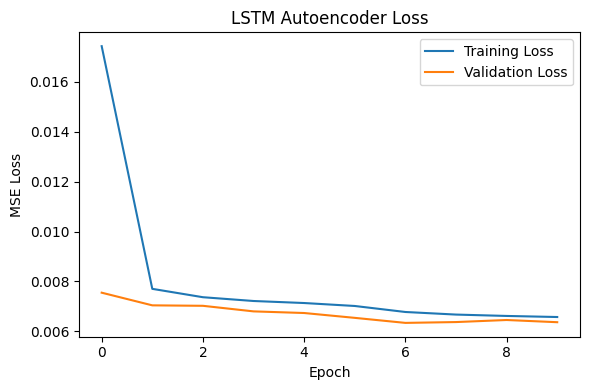

In [1]:
# 3D - Fault Detection in NASA Turbofan Engine Sensor Data using LSTM Autoencoder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report
from tensorflow import keras


# 1. LOAD + SCALE
data = pd.read_csv("NASA TurboFan Engine.csv")

# Separate features and fault labels
features = data.drop(
    ["unit", "cycle", "RUL", "Fault_Label"],
    axis=1
).values

labels = data["Fault_Label"].values       # 0 = Healthy, 1 = Faulty

# Scale features between 0 and 1
scaler = MinMaxScaler()
features = scaler.fit_transform(features)


# 2. CREATE TIME WINDOWS OF 10 ROWS
x, y = [], []

for i in range(len(features) - 10):
    x.append(features[i:i + 10])
    y.append(labels[i + 9])

x = np.array(x)
y = np.array(y)


# 3. USE ONLY HEALTHY DATA FOR TRAINING
x_normal = x[y == 0]


# 4. CREATE LSTM AUTOENCODER
n = x.shape[2]

model = keras.Sequential([
    # Encoder
    keras.layers.Input(shape=(10, n)),
    keras.layers.LSTM(32),

    # Repeat encoded representation
    keras.layers.RepeatVector(10),

    # Decoder
    keras.layers.LSTM(32, return_sequences=True),
    keras.layers.TimeDistributed(
        keras.layers.Dense(n)
    )
])


# 5. COMPILE MODEL
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()


# 6. TRAIN THE MODEL
# Input = Output because this is an autoencoder
history = model.fit(
    x_normal,
    x_normal,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)


# 7. RECONSTRUCT ALL SEQUENCES
reconstructed = model.predict(x, verbose=0)


# 8. CALCULATE RECONSTRUCTION ERROR
error = np.mean(
    np.square(x - reconstructed),
    axis=(1, 2)
)


# 9. SET FAULT DETECTION THRESHOLD
# 95th percentile of healthy engine reconstruction errors
threshold = np.percentile(error[y == 0], 95)

print("\nThreshold:", threshold)


# 10. PREDICT FAULTS
# High reconstruction error = faulty engine
y_pred = (error > threshold).astype(int)


# 11. DISPLAY CLASSIFICATION RESULTS
print("\nClassification Report:")
print(classification_report(y, y_pred))


# 12. PLOT TRAINING AND VALIDATION LOSS
plt.figure(figsize=(6, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Autoencoder Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()

plt.tight_layout()
plt.show()